# **Prévoir le taux d'occupation des trains Transilien**

[Data Challenge ENS × SNCF-Transilien](https://challengedata.ens.fr/challenges/89) : prévoir le **taux d'occupation d'un train à la station suivante**, pour informer les voyageurs en temps réel de l'affluence.



# **Partie 1 : explorer les données**

## 1. Imports et chargement

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)

In [2]:
from pathlib import Path

if not all(Path(f).exists() for f in ["Xtrain.csv", "Ytrain.csv", "Xtest.csv"]):
    from google.colab import files
    files.upload()

In [3]:
X_train = pd.read_csv("Xtrain.csv", parse_dates=["date"])
y_train = pd.read_csv("Ytrain.csv")["p0q0"]
X_test = pd.read_csv("Xtest.csv", parse_dates=["date"])

# Un seul tableau d'entraînement, avec la cible : plus pratique pour explorer
train = X_train.assign(p0q0=y_train)

print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
train.head()

Entraînement : (31119, 12) | Test : (13752, 12)


,date,train,way,station,hour,composition,p1q0,p2q0,p3q0,p0q1,p0q2,p0q3,p0q0
0,2019-01-07,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.201,0.138,0.091,0.216
1,2019-01-08,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.204,0.152,0.106,0.216
2,2019-01-10,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.213,0.153,0.111,0.227
3,2019-01-11,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.213,0.152,0.108,0.229
4,2019-01-14,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.210,0.147,0.096,0.225


In [4]:
train.describe()

,date,train,way,composition,p1q0,p2q0,p3q0,p0q1,p0q2,p0q3,p0q0
count,31119,31119.000000,31119.0,31119.000000,29067.000000,26974.000000,24935.000000,27917.000000,24720.000000,21527.000000,31119.000000
mean,2019-03-07 05:09:45.481538560,27.067965,0.0,1.999647,0.234769,0.251392,0.316867,0.207200,0.222167,0.209845,0.248754
min,2019-01-07 00:00:00,1.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.004000,0.004000,0.004000,0.000000
25%,2019-01-31 00:00:00,13.000000,0.0,2.000000,0.094000,0.136000,0.196000,0.099000,0.107000,0.100000,0.121000
50%,2019-03-12 00:00:00,26.000000,0.0,2.000000,0.192000,0.230000,0.312000,0.181000,0.188000,0.172000,0.220000
75%,2019-04-05 00:00:00,41.000000,0.0,2.000000,0.363000,0.354000,0.420000,0.294000,0.322000,0.292000,0.360500
max,2019-05-20 00:00:00,55.000000,0.0,2.000000,0.934000,0.937000,0.937000,0.969000,0.974000,0.974000,0.974000
std,NaN,15.979186,0.0,0.018798,0.166153,0.143506,0.150974,0.134709,0.147600,0.144858,0.157367


### Les variables

| Colonne | Signification |
|---|---|
| `p0q0` (**cible**) | Taux d'occupation du train k à la station s le jour d (passagers à bord / capacité), entre 0 et 1 |
| `date`, `hour` | Jour et créneau horaire |
| `train`, `station` | Identifiant du train (de 1 à 55 dans la journée) et de la station |
| `way` | Sens : 0 vers Paris, 1 vers la banlieue |
| `composition` | Nombre de rames (1 ou 2) |
| `p1q0`, `p2q0`, `p3q0` | Occupation des 1, 2 et 3 **trains précédents** à la même station |
| `p0q1`, `p0q2`, `p0q3` | Occupation du **même train** aux 1, 2 et 3 **stations précédentes** |

## 2. La cible : le taux d'occupation

count    31119.000
mean         0.249
std          0.157
min          0.000
25%          0.121
50%          0.220
75%          0.360
max          0.974
Name: p0q0, dtype: float64


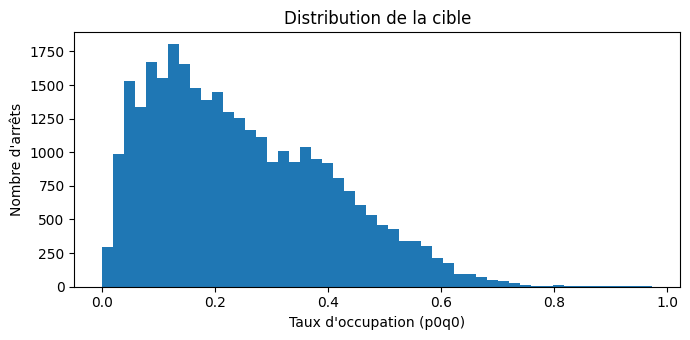

In [5]:
print(y_train.describe().round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(y_train, bins=50)
ax.set_xlabel("Taux d'occupation (p0q0)")
ax.set_ylabel("Nombre d'arrêts")
ax.set_title("Distribution de la cible")
plt.tight_layout()
plt.show()

**Les trains sont plutôt peu remplis.** La moitié des arrêts sont sous 22 %, et très peu dépassent 60 %. C’est logique : un train se remplit progressivement le long de sa ligne. Les premières stations, où il est presque vide, tirent la distribution vers le bas.

**La distribution est asymétrique** : la queue s’étire vers la droite. La moyenne (0,249) est plus grande que la médiane (0,220), car les quelques trains bondés tirent la moyenne vers le haut.


## 3. Comment sont séparés entraînement et test ?


Entraînement : du 2019-01-07 au 2019-05-20 | 74 jours
Test         : du 2019-05-21 au 2019-07-05 | 30 jours
Jours communs : 0


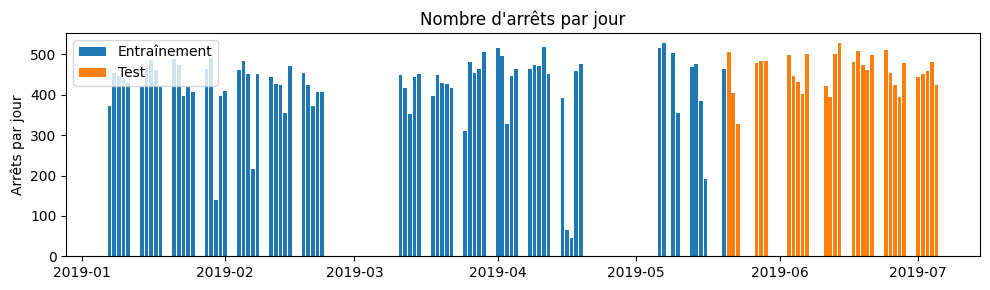

In [6]:
print("Entraînement : du", X_train.date.min().date(), "au", X_train.date.max().date(), "|", X_train.date.nunique(), "jours")
print("Test         : du", X_test.date.min().date(), "au", X_test.date.max().date(), "|", X_test.date.nunique(), "jours")
print("Jours communs :", len(set(X_train.date) & set(X_test.date)))

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(X_train.date.value_counts().index, X_train.date.value_counts().values, label="Entraînement")
ax.bar(X_test.date.value_counts().index, X_test.date.value_counts().values, label="Test")
ax.set_ylabel("Arrêts par jour")
ax.set_title("Nombre d'arrêts par jour")
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
# Quels jours de semaine manquent entre le 7 janvier et le 5 juillet ?
all_weekdays = pd.bdate_range(X_train.date.min(), X_test.date.max())
missing = sorted(set(all_weekdays) - set(X_train.date) - set(X_test.date))
print(len(missing), "jours ouvrés absents :")
print([d.strftime("%d/%m") for d in missing])

print("\nJours de la semaine présents (0 = lundi, ..., 6 = dimanche) :", sorted(X_train.date.dt.dayofweek.unique()))

26 jours ouvrés absents :
['25/02', '26/02', '27/02', '28/02', '01/03', '04/03', '05/03', '06/03', '07/03', '08/03', '22/04', '23/04', '24/04', '25/04', '26/04', '29/04', '30/04', '01/05', '02/05', '03/05', '08/05', '17/05', '24/05', '30/05', '31/05', '10/06']

Jours de la semaine présents (0 = lundi) : [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]


Les jours présents sont uniquement du lundi au vendredi.
De plus dans les 26 jours ouvrés absents, on remarque que les données ne couvrent que les jours ouvrés hors vacances scolaires.  
Le modèle apprendra donc le comportement d’un jour de semaine « normal ».

In [8]:
arrets_par_jour = train.groupby("date").size()
print(arrets_par_jour.describe().round(1))

count     74.0
mean     420.5
std       91.5
min       46.0
25%      406.2
50%      447.5
75%      468.2
max      527.0
dtype: float64


In [9]:
print(train.groupby("date").size().sort_values().head(10))

date
2019-04-17     46
2019-04-16     65
2019-01-30    139
2019-05-16    192
2019-02-07    216
2019-03-25    311
2019-04-03    328
2019-03-13    352
2019-05-10    355
2019-02-14    355
dtype: int64


## 4. Les variables de contexte

In [10]:
for col in ["way", "composition", "hour"]:
    print(f"--- {col} ---")
    print(train[col].value_counts(dropna=False).sort_index().to_string(), "\n")

print("Stations du test absentes de l'entraînement :", set(X_test.station) - set(train.station))
print("Trains du test absents de l'entraînement   :", set(X_test.train) - set(train.train))

couples_train = set(zip(train.train, train.station))
couples_test = set(zip(X_test.train, X_test.station))
print("Couples (train, station) du test absents de l'entraînement :", len(couples_test - couples_train))

--- way ---
way
0    31119 

--- composition ---
composition
1       11
2    31108 

--- hour ---
hour
06:00:00     4995
07:00:00    10064
08:00:00    10028
09:00:00     2826
11:00:00        2
NaN          3204 

Stations du test absentes de l'entraînement : set()
Trains du test absents de l'entraînement   : set()
Couples (train, station) du test absents de l'entraînement : 0


`way` vaut toujours 0 et `composition` vaut presque toujours 2 : ces deux variables ne varient pas et ne seront pas utilisées. Toutes les stations, tous les trains et tous les couples (train, station) du test existent dans l'entraînement.

In [11]:
# Le seul cas de train avec une seule rame (composition = 1)
une_rame = train[train.composition == 1]
print(une_rame[["date", "train", "station", "hour", "p0q0"]])
print(f"\nOccupation moyenne avec 1 rame : {une_rame.p0q0.mean():.2f}")

meme_train = train[(train.train == 9) & train.station.isin(une_rame.station) & (train.composition == 2)]
print(f"Même train, mêmes stations, occupation moyenne avec 2 rames : {meme_train.p0q0.mean():.2f}")

            date  train station      hour   p0q0
30529 2019-01-30      9      AD  08:00:00  0.963
30588 2019-01-30      9      AI  09:00:00  0.969
30647 2019-01-30      9      AJ  09:00:00  0.969
30706 2019-01-30      9      AK  08:00:00  0.974
30765 2019-01-30      9      AM  08:00:00  0.933
30824 2019-01-30      9      AT  08:00:00  0.677
30883 2019-01-30      9      AW  08:00:00  0.469
30942 2019-01-30      9      AX       NaN  0.289
31001 2019-01-30      9      BB  09:00:00  0.939
31059 2019-01-30      9      BD  08:00:00  0.354
31118 2019-01-30      9      BE  08:00:00  0.416

Occupation moyenne avec 1 rame : 0.72
Même train, mêmes stations, occupation moyenne avec 2 rames : 0.31


In [12]:
# Les heures manquantes : à quoi correspondent-elles ?
no_hour = train.hour.isna()
print(f"Heure manquante : {no_hour.mean():.1%} des arrêts")
print(f"Parmi eux, p0q1 (station précédente) est aussi manquant : {train.loc[no_hour, 'p0q1'].isna().mean():.1%}")
print(f"Occupation moyenne quand l'heure manque : {train.loc[no_hour, 'p0q0'].mean():.3f} (moyenne générale : {train.p0q0.mean():.3f})")

Heure manquante : 10.3% des arrêts
Parmi eux, p0q1 (station précédente) est aussi manquant : 91.1%
Occupation moyenne quand l'heure manque : 0.077 (moyenne générale : 0.249)


**Une heure manquante signale un début de ligne**  
10,3 % des arrêts n'ont pas d'heure. Dans 91 % des cas, l'occupation à la station précédente (`p0q1`) manque aussi : le train est à sa première station, et il est presque vide (occupation moyenne de 0,077 contre 0,249).

Cette absence porte une information : les heures manquantes sont donc conservées telles quelles, sans être remplacées par une valeur arbitraire.

## 5. Les profils d'occupation

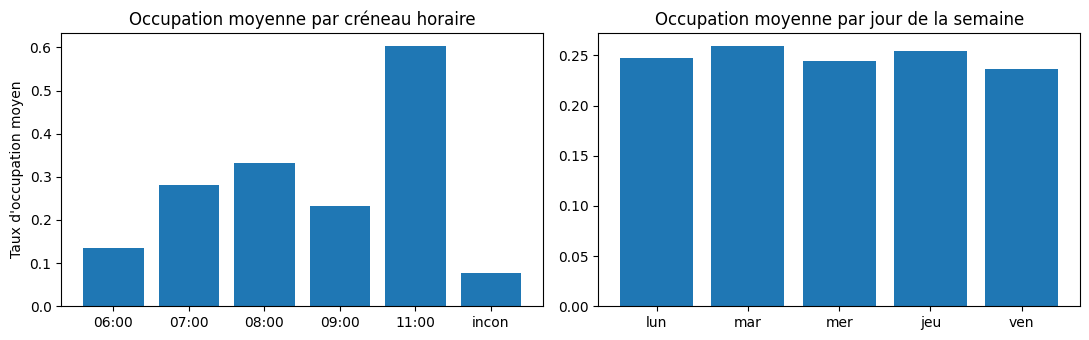

,mean,size
hour,,
06:00:00,0.134,4995
07:00:00,0.281,10064
08:00:00,0.333,10028
09:00:00,0.232,2826
11:00:00,0.603,2
inconnue,0.077,3204


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

by_hour = train.groupby(train.hour.fillna("inconnue")).p0q0.agg(["mean", "size"])
axes[0].bar(by_hour.index.str[:5], by_hour["mean"])
axes[0].set_title("Occupation moyenne par créneau horaire")
axes[0].set_ylabel("Taux d'occupation moyen")

days = ["lun", "mar", "mer", "jeu", "ven"]
by_dow = train.groupby(train.date.dt.dayofweek).p0q0.mean()
axes[1].bar([days[d] for d in by_dow.index], by_dow.values)
axes[1].set_title("Occupation moyenne par jour de la semaine")

plt.tight_layout()
plt.show()
by_hour.round(3)

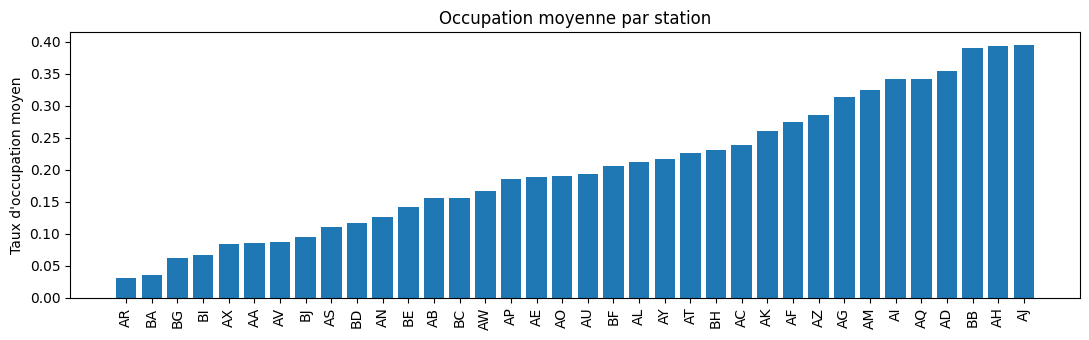

In [14]:
by_station = train.groupby("station").p0q0.mean().sort_values()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(by_station.index, by_station.values)
ax.set_title("Occupation moyenne par station")
ax.set_ylabel("Taux d'occupation moyen")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Si un train donné passe à une station donnée toujours à peu près à la même heure alors l’heure n’apportera donc presque plus d’information nouvelle.  

In [15]:
# Combien de la variance de la cible s'explique par le seul couple (train, station) ?
node_mean = train.groupby(["train", "station"]).p0q0.transform("mean") # Calcule la moyenne d'occupation de chaque couple
r2 = 1 - ((train.p0q0 - node_mean) ** 2).mean() / train.p0q0.var(ddof=0) # Calcule du coefficient de détermination
print(f"Nombre de couples (train, station) : {train.groupby(['train', 'station']).ngroups}")
print(f"Part des variations de l’occupation on peut prévoir en connaissant seulement le couple (train, station) : {r2:.1%}")

Nombre de couples (train, station) : 541
Part des variations de l’occupation on peut prévoir en connaissant seulement le couple (train, station) : 93.9%


Connaître seulement le train et la station permet d’expliquer 94 % des variations du taux d’occupation : d’un jour à l’autre, un même train est rempli à peu près pareil à une même station.  
Les 6 % restants correspondent aux variations quotidiennes.

## 6. Les variables de décalage

In [16]:
lags = ["p1q0", "p2q0", "p3q0", "p0q1", "p0q2", "p0q3"]
summary = pd.DataFrame({
    "% manquant (train)": train[lags].isna().mean().mul(100).round(1),
    "% manquant (test)": X_test[lags].isna().mean().mul(100).round(1),
})
summary

,% manquant (train),% manquant (test)
p1q0,6.6,6.2
p2q0,13.3,12.7
p3q0,19.9,19.3
p0q1,10.3,10.2
p0q2,20.6,20.4
p0q3,30.8,30.5


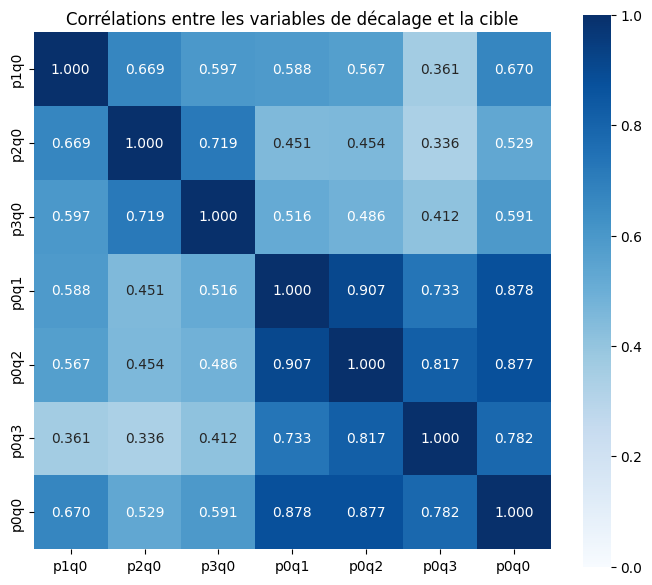

In [17]:
import seaborn as sns

corr = train[lags + ["p0q0"]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax)
ax.set_title("Corrélations entre les variables de décalage et la cible")
plt.tight_layout()
plt.show()

**Matrice de corrélation.** Les variables du même train (`p0q1`, `p0q2`, `p0q3`) forment un bloc très redondant (jusqu'à 0,91), distinct de celui des trains précédents (`p1q0`, `p2q0`, `p3q0`, 0,60 à 0,72).  
Le modèle disposera de deux sources d'information en partie distinctes, mais devra se partager l'importance entre des variables qui disent presque la même chose, comme `p0q1` et `p0q2`.

## **Conclusion de l'exploration**

**1. Le test est dans le futur.** L'entraînement couvre du 7 janvier au 20 mai 2019, le test du 21 mai au 5 juillet 2019, sans aucun jour en commun. Les deux périodes ne contiennent que des jours ouvrés hors vacances : les 26 jours ouvrés absents correspondent aux vacances scolaires d'hiver et de printemps (zone C), aux jours fériés et à deux vendredis inexpliqués (17/05 et 24/05).

**2. Le couple (train, station) porte l'essentiel de l'information.** Connaître seulement le train et la station permet d'expliquer 94 % des variations du taux d'occupation : d'un jour à l'autre, un même train est rempli à peu près pareil à une même station. Tous les trains, stations et couples du test sont présents dans l'entraînement.

**3. Les variations du jour passent par le même train en amont.** Les occupations du même train aux stations précédentes (`p0q1`, `p0q2`, `p0q3`) sont les plus corrélées à la cible (0,78 à 0,88) : si le train est plus plein que d'habitude en amont, il le sera aussi à la station suivante. Les trains précédents à la même station y sont moins liés (0,53 à 0,67).

**4. Les valeurs manquantes ont un sens.** Une heure ou un `p0q1` manquant signale le plus souvent une première station (train presque vide, occupation moyenne de 0,077) ; un `p1q0` manquant signale le premier train de la matinée à cette station.

### Les décisions pour la suite

| Décision | Raison |
|---|---|
| **Validation par date** : entraîner sur les premières semaines, valider sur les dernières, sans jour commun | Reproduire la situation du test, qui porte sur des jours jamais vus |
| **Variables gardées** : `train`, `station`, `hour`, jour de la semaine, les six variables de décalage | Elles apportent de l'information et existent dans l'entraînement comme dans le test |
| **Variables écartées** : année, mois, `way`, `composition` | L'année vaut toujours 2019 ; juin et juillet, présents dans le test, n'apparaissent jamais dans l'entraînement ; `way` vaut toujours 0 ; `composition` vaut 2 partout sauf 11 arrêts d'un seul train, et toujours 2 dans le test |
| **Valeurs manquantes conservées telles quelles** | Elles signalent un début de ligne ou un premier train ; on utilisera un modèle qui les gère nativement |
| **Jours incomplets conservés** | Chaque arrêt présent reste une observation valide |
| **Prédictions ramenées entre 0 et 1** | La cible est un taux d'occupation |

### Les limites
- Le test porte sur une période jamais observée (fin mai à début juillet) : un éventuel effet de saison ne pourra pas être appris.
- Cinq jours de l'entraînement sont incomplets (moins de la moitié des quelque 450 arrêts habituels), sans explication connue.

# **Partie 2 : la validation et les modèles de référence**

Il faut une **validation** qui reproduit la situation du test, et des **modèles de référence** qui fixent un score minimum.

## 7. Séparer l'entraînement et la validation par date

Comme le test porte sur des jours **postérieurs** à l'entraînement, on coupe `train` à une date :
- **entraînement** : du 7 janvier au 12 avril ;
- **validation** : du 15 avril au 20 mai.

Aucun jour n'est commun aux deux parties. La validation représente environ 17 % des arrêts : assez pour mesurer l'erreur de façon fiable, tout en laissant l'essentiel des données pour apprendre.

In [18]:
CUTOFF = pd.Timestamp("2019-04-13")

tr = train[train.date < CUTOFF].copy()      # entraînement
va = train[train.date >= CUTOFF].copy()     # validation

print(f"Entraînement : {tr.date.min().date()} → {tr.date.max().date()} | {tr.date.nunique()} jours | {len(tr):,} arrêts")
print(f"Validation   : {va.date.min().date()} → {va.date.max().date()} | {va.date.nunique()} jours | {len(va):,} arrêts ({len(va) / len(train):.0%})")
print("Jours communs :", len(set(tr.date) & set(va.date)))

Entraînement : 2019-01-07 → 2019-04-12 | 60 jours | 25,793 arrêts
Validation   : 2019-04-15 → 2019-05-20 | 14 jours | 5,326 arrêts (17%)
Jours communs : 0


## 8. La mesure d'erreur

On mesure l'erreur de deux façons complémentaires :
- la **MAE** (erreur absolue moyenne) : la moyenne des écarts entre prédiction et réalité. Elle se lit directement : une MAE de 0,01 signifie qu'on se trompe en moyenne de **1 point d'occupation**. C'est la métrique du challenge ;
- la **RMSE** (racine de l'erreur quadratique moyenne) : les écarts sont mis au carré avant d'en faire la moyenne, ce qui pénalise davantage les grosses erreurs.

La fonction `evaluate` ramène les prédictions entre 0 et 1, calcule ces erreurs et enregistre le résultat.

In [19]:
results = {}

def evaluate(name, predictions):
    pred = np.clip(predictions, 0, 1)                    # un taux d'occupation est entre 0 et 1
    errors = pred - va.p0q0.to_numpy()                   # erreur de chaque arrêt
    mae = np.mean(np.abs(errors))                        # erreur absolue moyenne
    mse = np.mean(errors ** 2)                           # erreur quadratique moyenne
    results[name] = {"MAE": mae, "RMSE": np.sqrt(mse)}
    print(f"{name:<45} MAE = {mae:.4f} | RMSE = {np.sqrt(mse):.4f}")

## 9. Les modèles de référence



### 9.1 La moyenne globale

Le modèle le plus simple : prédire toujours l'occupation moyenne de l'entraînement. C'est le **plancher** : tout modèle doit faire mieux.

In [20]:
evaluate("Moyenne globale", np.full(len(va), tr.p0q0.mean()))

Moyenne globale                               MAE = 0.1260 | RMSE = 0.1498


### 9.2 La moyenne de chaque couple (train, station)

Pour chaque arrêt de la validation, on prédit l'occupation moyenne de son couple (train, station) **sur la période d'entraînement**. C'est le modèle qui expliquait 94 % de la variance en partie 1.

In [21]:
couple_mean = tr.groupby(["train", "station"]).p0q0.mean().rename("couple_mean")
va = va.join(couple_mean, on=["train", "station"])       # ajoute la moyenne du couple à chaque arrêt

print("Arrêts de validation sans couple connu :", va.couple_mean.isna().sum())
evaluate("Moyenne du couple (train, station)", va.couple_mean)

Arrêts de validation sans couple connu : 0
Moyenne du couple (train, station)            MAE = 0.0267 | RMSE = 0.0392


### 9.3 La prévision naïve : « comme à la station précédente »

On prédit que l'occupation sera la même qu'à la station précédente : `p0q0 = p0q1`. Quand `p0q1` manque (première station), on utilise la moyenne du couple.

In [22]:
evaluate("Naïf : occupation à la station précédente", va.p0q1.fillna(va.couple_mean))

Naïf : occupation à la station précédente     MAE = 0.0638 | RMSE = 0.0877


### 9.4 Le benchmark officiel du challenge

La SNCF propose comme référence une **régression linéaire par couple (train, station)**, à partir de deux variables : `p1q0` (train précédent) et `p0q1` (station précédente).

Pour chacun des 541 couples, on entraîne donc une petite régression sur ses propres arrêts. Pour un couple dont une variable manque toujours (première station, ou premier train de la matinée), on ne garde que la variable disponible. Si aucune ne l'est, on prédit la moyenne du couple.

In [23]:
from sklearn.linear_model import LinearRegression

benchmark = va.couple_mean.copy()          # par défaut : la moyenne du couple

for (train_id, station), group in tr.groupby(["train", "station"]):    # découper l’entraînement en 541 couples
    features = [c for c in ["p1q0", "p0q1"] if group[c].notna().all()]   # les 2 variables sont disponibles pour ce couple
    if not features:
        continue                                                         # aucune variable : on garde la moyenne
    model = LinearRegression().fit(group[features], group.p0q0)            # ajuster les coefficients de la regression linéaire au couple
    rows = (va.train == train_id) & (va.station == station)                # repérer les arrêts du couple dans la validation

    if rows.any():
        benchmark[rows] = model.predict(va.loc[rows, features])
evaluate("Benchmark officiel (régression par couple)", benchmark)

Benchmark officiel (régression par couple)    MAE = 0.0121 | RMSE = 0.0227


In [24]:
baselines = pd.DataFrame(results).T
baselines["MAE (points)"] = (baselines.MAE * 100).round(2)
baselines["RMSE (points)"] = (baselines.RMSE * 100).round(2)
display(baselines.round(5))

,MAE,RMSE,MAE (points),RMSE (points)
Moyenne globale,0.12597,0.14978,12.60,14.98
"Moyenne du couple (train, station)",0.02669,0.03919,2.67,3.92
Naïf : occupation à la station précédente,0.06384,0.08775,6.38,8.77
Benchmark officiel (régression par couple),0.01209,0.02273,1.21,2.27


## **Conclusion des modèles de référence**

**Le benchmark officiel est la meilleure des références, avec une erreur moyenne de 1,2 point d'occupation (MAE) et une RMSE de 2,3 points.**  
La régression ajustée couple par couple capte à la fois le niveau habituel de chaque arrêt et l'information du jour, grâce à `p0q1` (même train) et `p1q0` (trains précédents).


# **Partie 3 : Gradient boosting**

*Le gradient boosting a été retenu après une comparaison rapide, réalisée en dehors de ce notebook, sur la même validation : il obtient la même MAE qu'une forêt aléatoire (0,0108) et fait mieux qu'une régression linéaire Ridge (0,0117). À précision égale, il a été préféré car il s'entraîne environ 9 fois plus vite que la forêt aléatoire et gère nativement les valeurs manquantes et les variables catégorielles.*

## 10. Le principe du gradient boosting

### Le boosting
1. Le 1ᵉʳ arbre fait une prédiction grossière.
2. On calcule les **erreurs** (les résidus) de cette prédiction.
3. Le 2ᵉ arbre apprend à prédire **ces erreurs**, et on ajoute une petite fraction de sa prédiction à la précédente. Cette fraction est le *learning rate*.
4. On recommence des centaines de fois : chaque arbre corrige un peu ce que les précédents ont raté.

### Pourquoi ce modèle convient à nos données
- **Il gère les valeurs manquantes nativement** : à chaque question, il apprend de quel côté envoyer les `NA`. Il peut donc apprendre « pas de station précédente → train presque vide ».
- **Il gère les variables catégorielles** comme `station` : il peut regrouper des stations qui se ressemblent, sans les ordonner arbitrairement.
- **Il capte les interactions** (« à telle station, quand `p0q1` est élevé… ») sans qu'on les écrive à la main.


## 11. Les variables du modèle

`train`, `station`, `hour`, jour de la semaine et les six variables de décalage.

Les valeurs manquantes restent manquantes.

`station` est un code texte (« AD », « AR »…) : on le transforme en numéro.

In [25]:
STATIONS = sorted(train.station.unique())                 # liste fixe : même numéro partout
LAGS = ["p1q0", "p2q0", "p3q0", "p0q1", "p0q2", "p0q3"]


def make_features(df):
    features = pd.DataFrame(index=df.index)
    features["train"] = df.train
    features["station"] = pd.Categorical(df.station, categories=STATIONS).codes   # transforme station en numéro
    features["hour"] = pd.to_numeric(df.hour.str[:2])     # "08:00:00" -> 8, et NA reste NA
    features["day_of_week"] = df.date.dt.dayofweek        # 0 = lundi ... 4 = vendredi
    features[LAGS] = df[LAGS]
    return features


F_tr, F_va = make_features(tr), make_features(va)
F_tr.head()

,train,station,hour,day_of_week,p1q0,p2q0,p3q0,p0q1,p0q2,p0q3
0,1,3,6.0,0,NaN,NaN,NaN,0.201,0.138,0.091
1,1,3,6.0,1,NaN,NaN,NaN,0.204,0.152,0.106
2,1,3,6.0,3,NaN,NaN,NaN,0.213,0.153,0.111
3,1,3,6.0,4,NaN,NaN,NaN,0.213,0.152,0.108
4,1,3,6.0,0,NaN,NaN,NaN,0.210,0.147,0.096


## 12. Premier modèle lambda

Les réglages principaux :
- `categorical_features` : `train` et `station` ;
- `learning_rate=0.05` et `max_iter=500` : 500 arbres, chacun corrigeant 5 % de l'erreur restante ;
- `early_stopping=False` : l'arrêt anticipé de scikit-learn utilise une validation tirée **au hasard parmi les lignes**, ce qui mélange les jours. On s'en passe pour rester cohérent avec notre validation par date ;
- `random_state=0` : des résultats reproductibles.

In [26]:
from sklearn.ensemble import HistGradientBoostingRegressor

model = HistGradientBoostingRegressor(
    categorical_features=["train", "station"],
    learning_rate=0.05,
    max_iter=500,
    early_stopping=False,
    random_state=0,
)
model.fit(F_tr, tr.p0q0)

evaluate("Gradient boosting", model.predict(F_va))

Gradient boosting                             MAE = 0.0108 | RMSE = 0.0190


In [27]:
# Erreur sur l'entraînement : pour repérer un éventuel surapprentissage
train_rmse = np.sqrt(np.mean((np.clip(model.predict(F_tr), 0, 1) - tr.p0q0) ** 2))
print(f"RMSE entraînement : {train_rmse:.4f} | RMSE validation : {results['Gradient boosting']['RMSE']:.4f}")

RMSE entraînement : 0.0132 | RMSE validation : 0.0190


**Surapprentissage.** L'erreur de validation (0,0190) est environ 1,4 fois celle d'entraînement (0,0132) : le modèle surapprend légèrement, ce qui est habituel pour un gradient boosting.

## 13. Régler les hyperparamètres

- `learning_rate` : la part de l'erreur corrigée par chaque arbre ;
- `max_iter` : le nombre d'arbres ;
- `max_leaf_nodes` : la taille de chaque arbre (nombre de feuilles).


In [28]:
import itertools, time

grid = []
start = time.time()
for lr, n_trees, leaves in itertools.product([0.05, 0.1], [300, 500, 1000], [31, 63]):
    m = HistGradientBoostingRegressor(categorical_features=["train", "station"], learning_rate=lr,
                                      max_iter=n_trees, max_leaf_nodes=leaves,
                                      early_stopping=False, random_state=0)
    m.fit(F_tr, tr.p0q0)
    rmse = np.sqrt(np.mean((np.clip(m.predict(F_va), 0, 1) - va.p0q0) ** 2))
    grid.append({"learning_rate": lr, "max_iter": n_trees, "max_leaf_nodes": leaves, "RMSE validation": rmse})

print(f"{len(grid)} combinaisons testées en {time.time() - start:.0f} s")
grid = pd.DataFrame(grid).sort_values("RMSE validation")
grid.round(5)

12 combinaisons testées en 67 s


,learning_rate,max_iter,max_leaf_nodes,RMSE validation
10,0.10,1000,31,0.01865
8,0.10,500,31,0.01870
4,0.05,1000,31,0.01872
5,0.05,1000,63,0.01880
9,0.10,500,63,0.01883
6,0.10,300,31,0.01883
3,0.05,500,63,0.01887
7,0.10,300,63,0.01888
11,0.10,1000,63,0.01893
2,0.05,500,31,0.01896


**Conclusion sur les hyperparamètres.** Le réglage des hyperparamètres a peu d'influence : les 12 combinaisons donnent des erreurs très proches (de 1,87 à 1,92 point d'occupation), et la meilleure n'améliore le premier modèle que de 1,6 %, un écart qui relève du bruit.  
On observe une tendance faible, et non systématique, en faveur d'un plus grand nombre d'arbres.

Pour la suite, on garde le premier modèle (`learning_rate=0.05`, `max_iter=500`, `max_leaf_nodes=31`) : il est plus simple et plus rapide, pour une performance équivalente.

## 14. Quelles variables comptent vraiment ?

On va faire une étude d'ablation afin de connaitre l'importance de chaque variable / groupe de variables.

In [29]:
def rmse_without(dropped):
    kept = [c for c in F_tr.columns if c not in dropped]
    m = HistGradientBoostingRegressor(categorical_features=[c for c in ["train", "station"] if c in kept],       # "train", "station" : variables catégorielles si pas retirées du modèle
                                      learning_rate=0.05, max_iter=500, early_stopping=False, random_state=0)    # mêmes paramètres que dans le premier modèle
    m.fit(F_tr[kept], tr.p0q0)
    return np.sqrt(np.mean((np.clip(m.predict(F_va[kept]), 0, 1) - va.p0q0) ** 2))


reference = results["Gradient boosting"]["RMSE"]
ablation = []
for name, dropped in [
    ("train et station", ["train", "station"]),
    ("les 6 variables de décalage", LAGS),
    ("p0q2 et p0q3 (stations plus en amont)", ["p0q2", "p0q3"]),
    ("p1q0, p2q0, p3q0 (trains précédents)", ["p1q0", "p2q0", "p3q0"]),
    ("hour", ["hour"]),
    ("day_of_week", ["day_of_week"]),
]:
    rmse = rmse_without(dropped)
    ablation.append({"variables retirées": name, "RMSE": rmse, "variation vs modèle complet": f"{(rmse / reference - 1):+.1%}"})

pd.DataFrame(ablation).set_index("variables retirées").round(5)

,RMSE,variation vs modèle complet
variables retirées,,
train et station,0.02486,+31.2%
les 6 variables de décalage,0.03925,+107.1%
p0q2 et p0q3 (stations plus en amont),0.02371,+25.1%
"p1q0, p2q0, p3q0 (trains précédents)",0.01880,-0.8%
hour,0.01879,-0.9%
day_of_week,0.01865,-1.6%


In [30]:
# Un modèle réduit aux variables utiles
SIMPLE = ["train", "station", "p0q1", "p0q2", "p0q3"]

model_simple = HistGradientBoostingRegressor(
    categorical_features=["train", "station"],
    learning_rate=0.05, max_iter=500, early_stopping=False, random_state=0,
)
model_simple.fit(F_tr[SIMPLE], tr.p0q0)

evaluate("Gradient boosting simplifié (5 variables)", model_simple.predict(F_va[SIMPLE]))

Gradient boosting simplifié (5 variables)     MAE = 0.0103 | RMSE = 0.0186


**Conclusion de l'ablation.**
- **Le couple (train, station) et les variables de décalage sont indispensables et complémentaires.** Le couple donne le niveau habituel de chaque arrêt, les variables de décalage l'écart du jour. Sans variables de décalage, le modèle ne fait pas mieux que la moyenne de chaque couple (RMSE de 0,039) ; sans le couple, l'erreur augmente de 31 %, les variables de décalage compensant en partie l'information perdue.

- **`p0q2` et `p0q3` sont très utiles (+25 % d'erreur sans elles)**, bien qu'elles soient très proches de `p0q1`. Disposer de plusieurs mesures du même train à différentes stations permet probablement au modèle de corriger les erreurs des capteurs de comptage : si une mesure est anormale, les autres permettent de la repérer.

- **Les trains précédents, l'heure et le jour de la semaine n'apportent rien** : le modèle fait même légèrement mieux sans eux. Un modèle réduit à `train`, `station`, `p0q1`, `p0q2` et `p0q3` obtient la même performance (RMSE de 0,0186 contre 0,0190) avec deux fois moins de variables.

## 15. Récapitulatif

In [31]:
summary = pd.DataFrame(results).T
summary["MAE (points)"] = (summary.MAE * 100).round(2)
summary["RMSE (points)"] = (summary.RMSE * 100).round(2)
summary.round(5)

,MAE,RMSE,MAE (points),RMSE (points)
Moyenne globale,0.12597,0.14978,12.60,14.98
"Moyenne du couple (train, station)",0.02669,0.03919,2.67,3.92
Naïf : occupation à la station précédente,0.06384,0.08775,6.38,8.77
Benchmark officiel (régression par couple),0.01209,0.02273,1.21,2.27
Gradient boosting,0.01084,0.01896,1.08,1.90
Gradient boosting simplifié (5 variables),0.01034,0.01862,1.03,1.86


## Conclusion de la partie 3

**1. Le gradient boosting bat le benchmark officiel.** Sa RMSE de validation est de 0,01896, contre 0,02273 pour le benchmark : l'erreur typique (RMSE) passe de 2,3 à 1,9 point d'occupation, soit 16,6 % d'erreur en moins.

**2. Le modèle surapprend légèrement.** Son erreur de validation est environ 1,4 fois celle d'entraînement (0,0190 contre 0,0132). Il n'a pas pour autant mémorisé les données : il se trompe encore de 1,3 point en moyenne sur les arrêts qu'il a appris. L'écart inclut aussi l'effet du changement de période entre l'entraînement et la validation.

**3. Le réglage des hyperparamètres a peu d'influence.** Les 12 combinaisons testées donnent des erreurs très proches (de 1,87 à 1,92 point), et la meilleure n'améliore le premier modèle que de 1,6 %, un écart qui relève du bruit.

**4. Ce sont les variables qui font la performance.**
- Le couple (train, station) et les variables de décalage du même train sont indispensables et complémentaires : le couple donne le niveau habituel de chaque arrêt, les variables de décalage l'écart du jour. Sans variables de décalage, l'erreur double (+107 %) ; sans le couple, elle augmente de 31 %.
- `p0q2` et `p0q3` sont très utiles (+25 % d'erreur sans elles), bien qu'elles soient très proches de `p0q1` : plusieurs mesures du même train permettent probablement de corriger les erreurs des capteurs de comptage.
- Les trains précédents, l'heure et le jour de la semaine n'apportent rien.

**5. Modèle retenu : le gradient boosting simplifié**, avec 5 variables (`train`, `station`, `p0q1`, `p0q2`, `p0q3`) et les réglages du premier modèle (`learning_rate=0.05`, `max_iter=500`, `max_leaf_nodes=31`). Il obtient la même performance que le modèle complet (RMSE de 0,0186) avec deux fois moins de variables.

# **Partie 4 : analyse des erreurs et prédictions finales**

1. Comprendre **où** le modèle se trompe, sur la validation.
2. Entraîner le modèle final sur **toutes** les données d'entraînement.
3. Prédire le test et créer le fichier de soumission au challenge.

## 16. Où le modèle se trompe-t-il ?

On analyse les erreurs du **modèle simplifié** (5 variables) sur la validation.

In [32]:
va["prediction"] = np.clip(model_simple.predict(F_va[SIMPLE]), 0, 1)
va["erreur"] = va.prediction - va.p0q0


def rmse(errors):
    return np.sqrt(np.mean(errors ** 2))


print(f"MAE globale         : {va.erreur.abs().mean():.4f}")
print(f"RMSE globale        : {rmse(va.erreur):.4f}")
print(f"Erreur moyenne (biais) : {va.erreur.mean():+.4f}")      # > (<) 0 le modèle surestime (sous-estime) l'occupation en moyenne
print(f"Arrêts avec plus de 5 points d'erreur  : {(va.erreur.abs() > 0.05).mean():.1%}")
print(f"Arrêts avec plus de 10 points d'erreur : {(va.erreur.abs() > 0.10).mean():.1%}")

MAE globale         : 0.0103
RMSE globale        : 0.0186
Erreur moyenne (biais) : +0.0025
Arrêts avec plus de 5 points d'erreur  : 1.7%
Arrêts avec plus de 10 points d'erreur : 0.4%


## 17. Le modèle final

Pour prédire le test, on réentraîne le modèle simplifié sur **toutes** les données d'entraînement (validation comprise).

In [33]:
F_all = make_features(train)
F_test = make_features(X_test)

final_model = HistGradientBoostingRegressor(categorical_features=["train", "station"], learning_rate=0.05,
                                            max_iter=500, early_stopping=False, random_state=0)
final_model.fit(F_all[SIMPLE], train.p0q0)

test_predictions = np.clip(final_model.predict(F_test[SIMPLE]), 0, 1)

## 18. Vérifier les prédictions et créer le fichier de soumission

On contrôle que les prédictions sont complètes et plausibles.

Prédictions manquantes    : 0
Minimum / maximum     : 0.008 / 0.868
Moyenne prédite (test) : 0.228 | moyenne réelle (entraînement) : 0.249


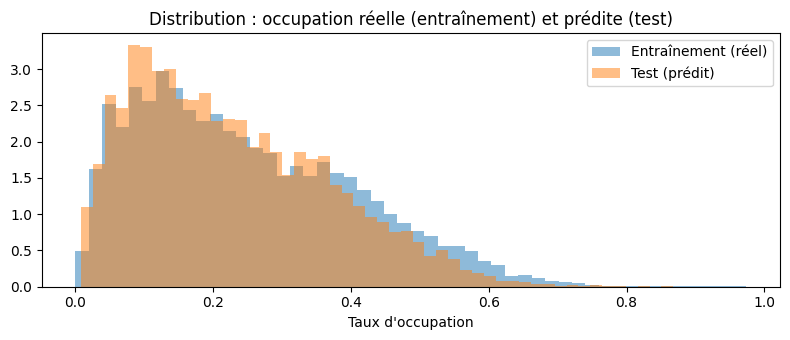

In [34]:
print(f"Prédictions manquantes    : {np.isnan(test_predictions).sum()}")
print(f"Minimum / maximum     : {test_predictions.min():.3f} / {test_predictions.max():.3f}")
print(f"Moyenne prédite (test) : {test_predictions.mean():.3f} | moyenne réelle (entraînement) : {train.p0q0.mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train.p0q0, bins=50, density=True, alpha=0.5, label="Entraînement (réel)")
ax.hist(test_predictions, bins=50, density=True, alpha=0.5, label="Test (prédit)")
ax.set_xlabel("Taux d'occupation")
ax.set_title("Distribution : occupation réelle (entraînement) et prédite (test)")
ax.legend()
plt.tight_layout()
plt.show()

In [35]:
# Même format que Ytrain.csv : une colonne d'index (1, 2, 3...) sans nom, puis p0q0
submission = pd.DataFrame({"p0q0": test_predictions}, index=pd.RangeIndex(1, len(test_predictions) + 1))
submission.to_csv("predictions_test.csv", index_label="")

try:
    from google.colab import files
    files.download("predictions_test.csv")
except ImportError:
    print("Fichier enregistré : predictions_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# **Conclusion générale**

## La question posée
Peut-on prévoir le taux d'occupation d'un train Transilien à la station suivante, à partir de ce qu'on sait déjà de ce train et des trains précédents ?

## Ce qui a été fait
- **Une exploration des données**, qui a guidé tous les choix suivants : le test porte sur des semaines postérieures à l'entraînement, le couple (train, station) explique 94 % des variations d'occupation, et les valeurs manquantes signalent un début de ligne ou un premier train.
- **Une validation par date** : entraînement du 7 janvier au 12 avril, validation du 15 avril au 20 mai, sans jour commun, pour reproduire la situation du test.
- **Des modèles de référence**, de la moyenne globale au benchmark officiel (une régression linéaire par couple train-station).
- **Un modèle de gradient boosting**, avec un réglage des hyperparamètres et une étude d'ablation pour mesurer l'apport de chaque groupe de variables.
- **Un modèle final** entraîné sur toutes les données, et des prédictions pour les 13 752 arrêts du test.

## Les résultats

| Modèle | MAE (validation) | RMSE (validation) |
|---|---|---|
| Moyenne globale | 0,1260 (12,6 points) | 0,150 |
| Moyenne du couple (train, station) | 0,0267 (2,7 points) | 0,039 |
| Benchmark officiel | 0,0121 (1,2 point) | 0,0227 |
| **Gradient boosting simplifié (5 variables)** | **0,0103 (1,0 point)** | **0,0186** |

**1. Le gradient boosting bat le benchmark officiel** : son erreur moyenne passe de 1,2 à 1,0 point d'occupation (MAE réduite de 15 %, RMSE réduite de 18 %). Le biais est quasi nul (+0,25 point) et les grosses erreurs sont rares : 1,7 % des arrêts ont plus de 5 points d'erreur.

**2. Deux sources d'information suffisent.** Le couple (train, station) donne le niveau habituel de chaque arrêt ; l'occupation du même train aux trois stations précédentes (`p0q1`, `p0q2`, `p0q3`) donne l'écart du jour. Le modèle final n'utilise que ces 5 variables : les trains précédents, l'heure et le jour de la semaine n'apportent rien.

**3. Les variables comptent bien plus que les réglages.** Le meilleur réglage des hyperparamètres n'améliore le modèle que de 1,6 %, alors que retirer `p0q2` et `p0q3` augmente l'erreur de 25 %, et retirer toutes les variables de décalage la double.


## Limites
- **Une période de test jamais observée.** Le test tombe en juin et juillet, des mois absents de l'entraînement : un effet de saison qui ne se refléterait pas dans les variables de décalage ne pourrait pas être anticipé.
- **Une seule période de validation.** Les résultats reposent sur 14 jours de validation, dont certains atypiques (après les vacances de printemps, ponts de mai).
- **Des données de capteurs imparfaites.** Certains jours sont incomplets, et l'utilité de `p0q2` et `p0q3` suggère des erreurs de mesure que le modèle compense en partie.
- **Des prédictions lissées.** Le modèle prédit l'occupation la plus probable : il ne peut pas anticiper les situations exceptionnelles, comme un incident ou une affluence inhabituelle.

## Pistes d'amélioration
- Une **validation glissante** sur plusieurs périodes successives, pour confirmer la stabilité des résultats.
- Une **analyse détaillée des erreurs**, par station et par niveau d'occupation, pour repérer les situations les moins bien prédites.


# **Score sur le test**

Les prédictions ont été soumises sur le site du challenge. **Score obtenu : 0,0112.**

Ce score est très proche de la MAE du modèle sur la validation (0,0103). Le modèle se trompe ainsi en moyenne de **1,1 point d'occupation** sur des semaines qu'il n'a jamais vues, une erreur à peine supérieure à celle mesurée sur la validation (+9 %). La validation par date donnait donc une estimation fiable de la performance réelle.